# 03 — Exploratory data analysis

**Purpose:** inspect aggregate demand, product-level demand distributions, zero-sales weeks, product activity and history length before feature engineering.

**Input:** `../data/processed/weekly_panel.csv`

These charts are descriptive. They help identify skew, intermittency and product heterogeneity; they do not establish that a forecasting model will perform well. The observed zero-demand product-week share in the supplied panel is approximately 53%.

### Business-wide weekly demand

This chart sums units across all products for each week. Look for broad changes, peaks and unusual weeks; aggregation can hide product-level differences.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

panel = pd.read_csv("../data/processed/weekly_panel.csv", parse_dates=["week"],
                    dtype={"StockCode": str})
print(panel.shape)

(407702, 5)


### Distribution of positive product-week demand

The histogram uses a logarithmic scale because positive weekly quantities are highly spread out. The printed zero-week share separately measures intermittency across the full panel.

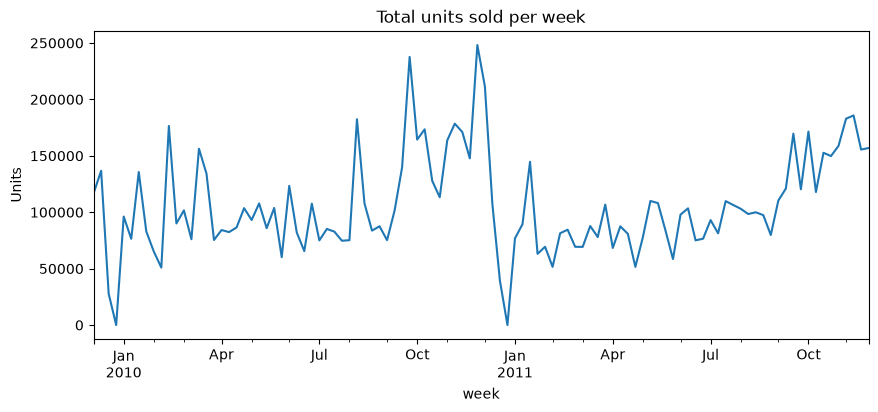

In [3]:
# Weekly Sales of whole Business
total = panel.groupby("week")["units"].sum()
plt.figure(figsize=(10, 4))
total.plot()
plt.title("Total units sold per week")
plt.ylabel("Units")
plt.show()

### Number of active products

This counts distinct products with positive sales in each week. It distinguishes the breadth of product activity from total units sold.

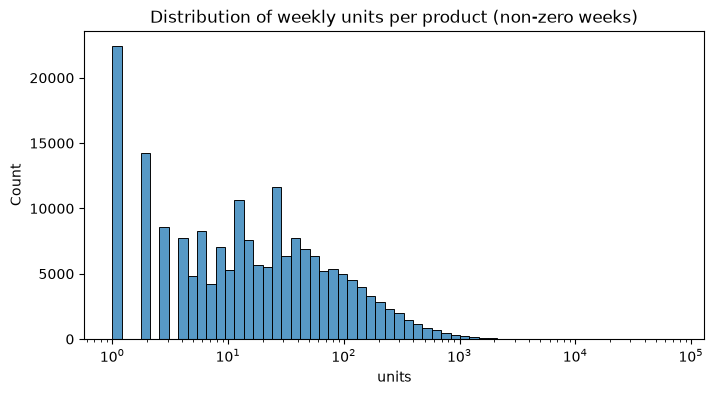

Share of zero weeks: 0.53


In [4]:
#Log Scale (Distribution of Units)
plt.figure(figsize=(8, 4))
sns.histplot(panel.loc[panel["units"] > 0, "units"], bins=60, log_scale=True)
plt.title("Distribution of weekly units per product (non-zero weeks)")
plt.show()
print("Share of zero weeks:", (panel["units"] == 0).mean().round(3))

### Highest-volume products

This ranks products by total units across the panel. A small number of high-volume products may contribute disproportionately to aggregate error metrics.

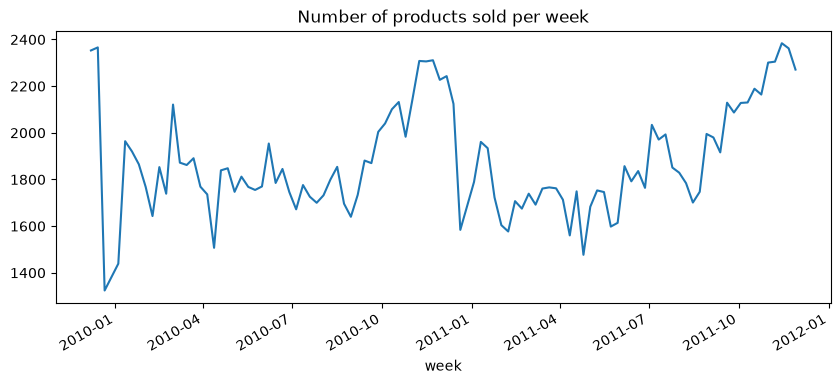

In [5]:
# How many products have been active (sold) each week
active = panel[panel["units"] > 0].groupby("week")["StockCode"].nunique()
plt.figure(figsize=(10, 4))
active.plot()
plt.title("Number of products sold per week")
plt.show()

### Product-history length

This shows how many weekly observations exist for each product. Different history lengths affect how much lagged information is available.

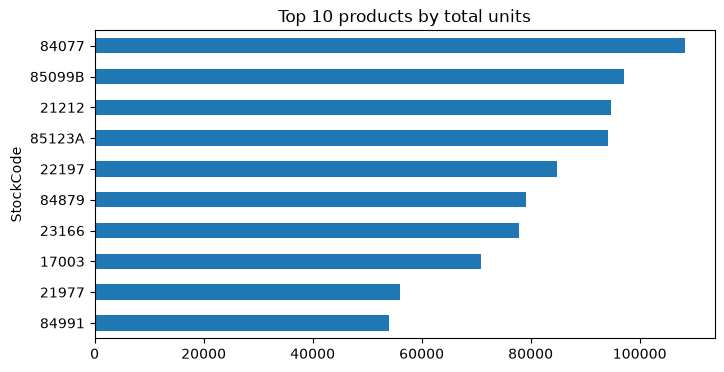

In [6]:
# Top 10 products
top = panel.groupby("StockCode")["units"].sum().nlargest(10)
top.plot(kind="barh", figsize=(8, 4))
plt.title("Top 10 products by total units")
plt.gca().invert_yaxis()
plt.show()

### Example product time series

The highest-volume product is plotted to illustrate how one product can have spikes and quieter periods that are not obvious from a business-wide total.

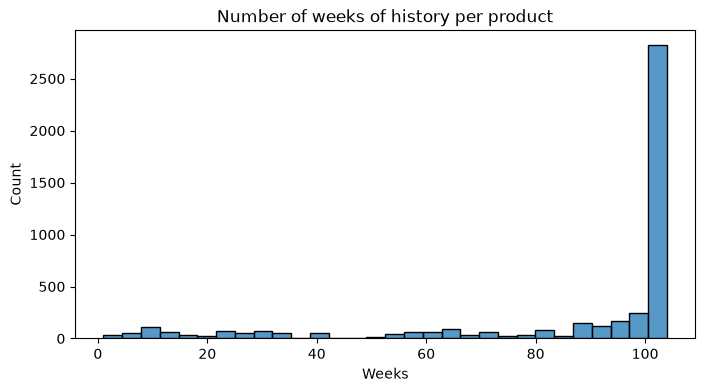

In [7]:
#the history of a single product
history = panel.groupby("StockCode").size()
plt.figure(figsize=(8, 4))
sns.histplot(history, bins=30)
plt.title("Number of weeks of history per product")
plt.xlabel("Weeks")
plt.show()

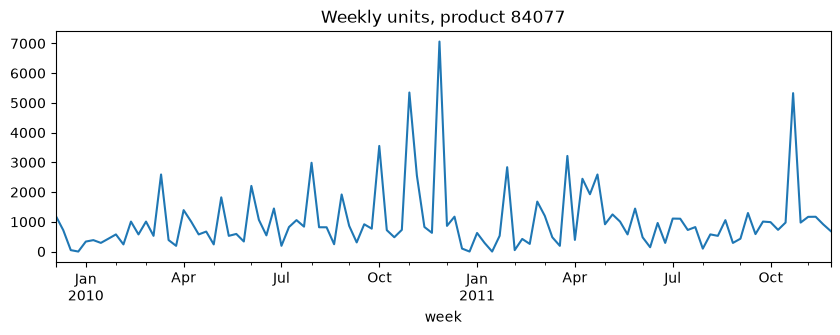

In [8]:
#Weekly pattern of a single product
code = top.index[0]
p = panel[panel["StockCode"] == code].set_index("week")["units"]
p.plot(figsize=(10, 3))
plt.title(f"Weekly units, product {code}")
plt.show()